In [1]:
import gensim.downloader as api

# approx. 1.6 GB
word2vec_model = api.load("word2vec-google-news-300")

# approx. 100 MB
# glove_model = api.load("glove-twitter-25")

# Task 1

In [2]:
import numpy as np

In [3]:
words = [
    # Royalty & Family (Linear relationships: king - man + woman = queen)
    "king",
    "queen",
    "prince",
    "princess",
    # Animals (Grouped by wild vs. domestic / species)
    "dog",
    "cat",
    "lion",
    "tiger",
    # Technology & Science (Technical and abstract domains)
    "computer",
    "algorithm",
    "physics",
    "telescope",
    # Food & Drink (Everyday sensory nouns)
    "coffee",
    "wine",
    "chocolate",
    "apple",
    # Abstract Concepts & Emotions (Intangible ideas)
    "happiness",
    "sorrow",
    "freedom",
    "justice",
]

In [4]:
import random

def project_embeddings_random(embeddings: np.ndarray, seed: int = 15):
    rng = random.Random(seed)
    embedding_size = embeddings.shape[1]
    dimensions = rng.sample(range(embedding_size), 3)
    print(f"Chosen dimensions: {dimensions}")
    
    projections = embeddings[:, dimensions]
    return projections

In [5]:
from sklearn.decomposition import PCA

def project_embeddings_pca(embeddings: np.ndarray, seed: int = 15):
    pca = PCA(3, random_state=seed)
    projections = pca.fit_transform(embeddings)
    return projections

In [6]:
from sklearn.manifold import TSNE

def project_embeddings_t_sne(embeddings: np.ndarray, seed: int = 15):
    embedding_size = embeddings.shape[0]
    t_sne = TSNE(3, random_state=seed, perplexity=embedding_size / 4)
    projections = t_sne.fit_transform(embeddings)
    return projections

In [7]:
import plotly
import plotly.graph_objs as go

In [8]:
def plot_projections(projections: np.ndarray, words: list[str], title: str):
    plotly.offline.init_notebook_mode()

    data = []
    trace = go.Scatter3d(
        x=projections[:, 0], 
        y=projections[:, 1],
        z=projections[:, 2],
        mode='markers',
        marker={
            'size': 10,
            'opacity': 0.7,
        },
        hovertext=words,
        hoverinfo="text",
        # hoverinfo="text+name",
        # name=topic,
    )
    data.append(trace)

    layout = go.Layout(
        margin={'l': 0, 'r': 0, 'b': 0, 't': 50},
        title=f"{title} Projection"
    )

    plot_figure = go.Figure(data=data, layout=layout)

    plotly.offline.iplot(plot_figure)

In [9]:
def plot_word_embeddings(model, words: list[str], embedding_type: str):
    embeddings = model[words]

    print("======================= Random Projection =======================")
    random_projections = project_embeddings_random(embeddings)
    print(random_projections)
    plot_projections(random_projections, words, f"{embedding_type} Random")

    print("======================= PCA Projection =======================")
    pca_projections = project_embeddings_pca(embeddings)
    print(pca_projections)
    plot_projections(pca_projections, words, f"{embedding_type} PCA")

    print("======================= t-SNE Projection =======================")
    t_sne_projections = project_embeddings_t_sne(embeddings)
    print(t_sne_projections)
    plot_projections(t_sne_projections, words, f"{embedding_type} t-SNE")

In [ ]:
# plot_word_embeddings(glove_model, words, "Glove")

======================= Random Projection =======================
Chosen dimensions: [6, 0, 16]
[[ 0.70118  -0.74501   0.36208 ]
 [ 1.1395   -1.1266   -0.11764 ]
 [ 0.80577  -1.3272    0.25803 ]
 [ 1.4337   -1.6816    0.40729 ]
 [ 1.2729   -1.242     0.95322 ]
 [ 1.3796   -0.96419   0.8706  ]
 [ 0.79862  -0.88983   0.24314 ]
 [ 0.79173  -0.70271   0.62697 ]
 [ 0.25917   0.64005   0.97678 ]
 [ 0.41564   0.79387  -0.13816 ]
 [ 1.6229    1.4935    0.78471 ]
 [ 0.30579  -0.78926   1.1849  ]
 [ 1.4566   -1.4532    1.2432  ]
 [ 1.2349   -1.5527    0.99669 ]
 [ 1.1505   -0.74392   0.87151 ]
 [ 0.010724  0.85337   0.54706 ]
 [ 1.9193   -0.64561  -0.27705 ]
 [ 1.3587   -0.96444   0.065411]
 [ 1.0521   -0.092769 -0.51337 ]
 [ 0.30482  -0.071487 -0.63618 ]]


======================= PCA Projection =======================
[[-1.1675655   0.87601316 -0.90871155]
 [-1.1713767   1.0981183  -0.55972874]
 [-1.1861584   1.6393914  -0.96820587]
 [-1.6388268   1.1464839  -0.06860479]
 [-1.6729487  -0.49952954 -0.44807073]
 [-1.3197812  -0.51310015 -0.6296006 ]
 [-0.7150214   0.7276964  -1.056716  ]
 [-0.61896825  0.56451154 -1.2389569 ]
 [ 1.6024165  -2.282712   -0.96588475]
 [ 3.6911848  -0.7922418  -0.6119746 ]
 [ 2.3626142  -1.621748    0.35884064]
 [ 1.8150612   0.19519956 -0.6129575 ]
 [-1.3455607  -1.4830176   1.3105443 ]
 [-1.2034936  -0.97544485  1.1729586 ]
 [-2.5542226  -2.2306848   1.6996068 ]
 [ 0.30504373 -1.815965   -1.3604748 ]
 [ 0.9216303   1.2697326   2.6341972 ]
 [ 1.4683381   1.4891454   2.675254  ]
 [ 1.2640718   1.4530786   0.5639758 ]
 [ 1.163561    1.7550733  -0.9854889 ]]


======================= t-SNE Projection =======================
[[ -31.968384  -110.86591     28.44686  ]
 [   0.505674   -83.323715    98.671364 ]
 [  17.13694     -9.317533    80.2024   ]
 [  17.951904   164.65793   -109.368744 ]
 [ -24.455275  -283.78424    -18.394535 ]
 [ -15.709955   148.20201     61.05119  ]
 [-153.89145    -14.145758   -28.22627  ]
 [ -32.83058     20.824589   167.71289  ]
 [ -45.110874    94.292206   -29.54312  ]
 [ 128.88228    -87.39364     10.305051 ]
 [ 126.5392      22.311846    35.066574 ]
 [ 106.879364  -131.47473    -48.02663  ]
 [  -6.2540865  -27.350737   -65.976524 ]
 [ -55.820343   -68.62472    -86.2995   ]
 [ -35.973217     9.164577  -145.19447  ]
 [  25.116848    84.8379     -19.11161  ]
 [  96.3371       1.4343348 -128.77867  ]
 [ 161.10612     -5.903162   -98.521996 ]
 [-107.55212     30.979086    68.72205  ]
 [-114.16693    -36.505672    88.98086  ]]


In [10]:
plot_word_embeddings(word2vec_model, words, "Word2Vec")

======================= Random Projection =======================
Chosen dimensions: [106, 5, 266]
[[-0.42773438 -0.03613281  0.02270508]
 [-0.57421875 -0.08886719  0.04418945]
 [-0.203125    0.10449219 -0.08251953]
 [-0.390625    0.00762939 -0.04125977]
 [-0.02172852  0.05737305 -0.16601562]
 [ 0.14257812  0.08300781 -0.15136719]
 [-0.06445312 -0.13671875 -0.27148438]
 [-0.09667969  0.02539062 -0.48632812]
 [-0.1640625   0.21679688 -0.13671875]
 [-0.67578125  0.05102539 -0.14160156]
 [ 0.14453125  0.20019531  0.37890625]
 [ 0.13867188 -0.05712891 -0.00891113]
 [ 0.15429688  0.02722168 -0.10986328]
 [ 0.09082031  0.23339844 -0.15429688]
 [ 0.29296875  0.01123047  0.00402832]
 [-0.06787109  0.16210938 -0.20605469]
 [-0.15625    -0.05908203 -0.04980469]
 [ 0.15332031 -0.08935547  0.36328125]
 [-0.1953125  -0.16015625  0.04614258]
 [-0.21875     0.02246094  0.16894531]]


======================= PCA Projection =======================
[[ 1.2236453   1.0032334  -0.7152933 ]
 [ 1.2782067   1.1784225  -0.8467395 ]
 [ 1.334957    1.1658926  -0.87080866]
 [ 1.4207647   1.2363085  -0.8258129 ]
 [ 0.6094627  -1.5848385  -0.26899356]
 [ 0.74819916 -1.7640349  -0.33797866]
 [ 0.9514455  -1.0757887  -0.6246957 ]
 [ 1.1218171  -1.8412287  -0.3494481 ]
 [-1.0297339  -0.1978783  -0.36341083]
 [-1.6835493   0.21717076 -1.1221184 ]
 [-1.6971028   0.7261183  -0.68612397]
 [-2.4243817   0.26740986 -1.516386  ]
 [-0.41644529 -0.72463727  1.1342021 ]
 [-0.6429323  -0.61469203  0.9310967 ]
 [-0.366153   -0.6130773   0.79907703]
 [-0.5056634  -0.8227012   0.32531622]
 [ 0.02739029  0.929759    1.2813914 ]
 [ 0.10411107  0.903547    1.6285647 ]
 [ 0.10704702  0.64519066  1.145005  ]
 [-0.16108401  0.96582544  1.2831559 ]]


======================= t-SNE Projection =======================
[[-118.92068    -84.192726    85.645    ]
 [  60.030308   -42.926003  -150.33147  ]
 [ -90.50617    -42.95977    156.8528   ]
 [   9.855042   -85.44918   -105.23372  ]
 [  98.646065    -6.9792147  -22.027872 ]
 [  31.517553     4.8572235  -12.044511 ]
 [ -71.37834    -16.859032   -19.287554 ]
 [-114.57662     49.74829     -1.7939029]
 [  13.649259    75.430374   -97.40853  ]
 [-211.91122    -42.321213    10.994427 ]
 [ 149.13983   -101.42906     49.259995 ]
 [  34.442055   155.782     -129.83543  ]
 [ -57.076527    39.179478  -125.99962  ]
 [  91.1801     129.25671     57.83854  ]
 [  95.50033     51.201393   110.16246  ]
 [  15.833164  -191.94118    -56.49111  ]
 [  -9.062123    -3.7406106   92.57705  ]
 [  36.843937   -55.973648   135.60641  ]
 [ -13.707522   -92.393524    49.620064 ]
 [ -33.024055   136.75903      9.671168 ]]


# Task 2

In [ ]:
# synonyms: big - huge
# antonyms: long - short
# same semantic field (hot drinks): coffee - cup
# unrelated words: cat - car; sorrow - pencil

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

def inspect_cosine_similarity(model):
    synonyms = ("big", "huge")
    antonyms = ("long", "short")
    same_semantic_field = ("coffee", "cup")
    unrelated_words = [("cat", "car"), ("sorrow", "pencil")]

    print(f"synonyms: ({synonyms[0]}, {synonyms[1]}) -> {cosine_similarity(model[synonyms[0]].reshape(1, -1), model[synonyms[1]].reshape(1, -1))}")
    print(f"antonyms: ({antonyms[0]}, {antonyms[1]}) -> {cosine_similarity(model[antonyms[0]].reshape(1, -1), model[antonyms[1]].reshape(1, -1))}")
    print(f"same_semantic_field: ({same_semantic_field[0]}, {same_semantic_field[1]}) -> {cosine_similarity(model[same_semantic_field[0]].reshape(1, -1), model[same_semantic_field[1]].reshape(1, -1))}")
    print("unrelated_words:")
    for unrelated_words_pair in unrelated_words:
        print(f"\t({unrelated_words_pair[0]}, {unrelated_words_pair[1]}) -> {cosine_similarity(model[unrelated_words_pair[0]].reshape(1, -1), model[unrelated_words_pair[1]].reshape(1, -1))}")

In [ ]:
# inspect_cosine_similarity(glove_model)

synonyms: (big, huge) -> [[0.88114023]]
antonyms: (long, short) -> [[0.89108187]]
same_semantic_field: (coffee, cup) -> [[0.71810436]]
unrelated_words:
	(cat, car) -> [[0.7421042]]
	(sorrow, pencil) -> [[0.41742665]]


In [12]:
inspect_cosine_similarity(word2vec_model)

synonyms: (big, huge) -> [[0.7809856]]
antonyms: (long, short) -> [[0.57684326]]
same_semantic_field: (coffee, cup) -> [[0.35601786]]
unrelated_words:
	(cat, car) -> [[0.21528184]]
	(sorrow, pencil) -> [[0.0537112]]


# Task 3

In [13]:
new_words = [
    # Royalty & Family
    "king",
    "queen",
    "prince",
    "princess",

    # Animals
    "dog",
    "cat",
    "lion",
    "tiger",

    # Technology & Science
    "computer",
    "algorithm",
    "physics",
    "telescope",

    # Food & Drink
    "coffee",
    "wine",
    "chocolate",
    "apple",

    # Abstract Concepts & Emotions
    "happiness",
    "sorrow",
    "freedom",
    "justice",

    # Five additional words
    "school",
    "doctor",
    "river",
    "music",
    "garden",
]

In [14]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

In [15]:
def plot_dendrogram(model, words, embedding_type):
    plt.figure(figsize=(14, 8))

    embeddings = model[words]

    linkage_matrix = linkage(
        embeddings,
        method="average",
        metric="cosine"
    )

    dendrogram(
        linkage_matrix,
        labels=words,
        leaf_rotation=90,
        leaf_font_size=10
    )

    plt.title(f"{embedding_type} Hierarchical Clustering of Word Embeddings")
    plt.xlabel("Words")
    plt.ylabel("Cosine Distance")
    plt.tight_layout()
    plt.show()

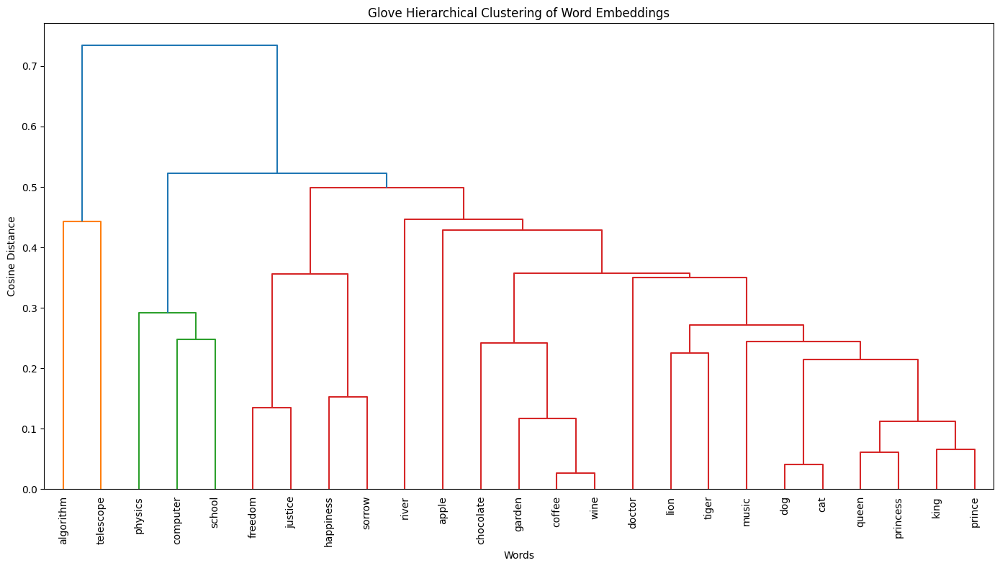

In [ ]:
# plot_dendrogram(glove_model, new_words, "Glove")

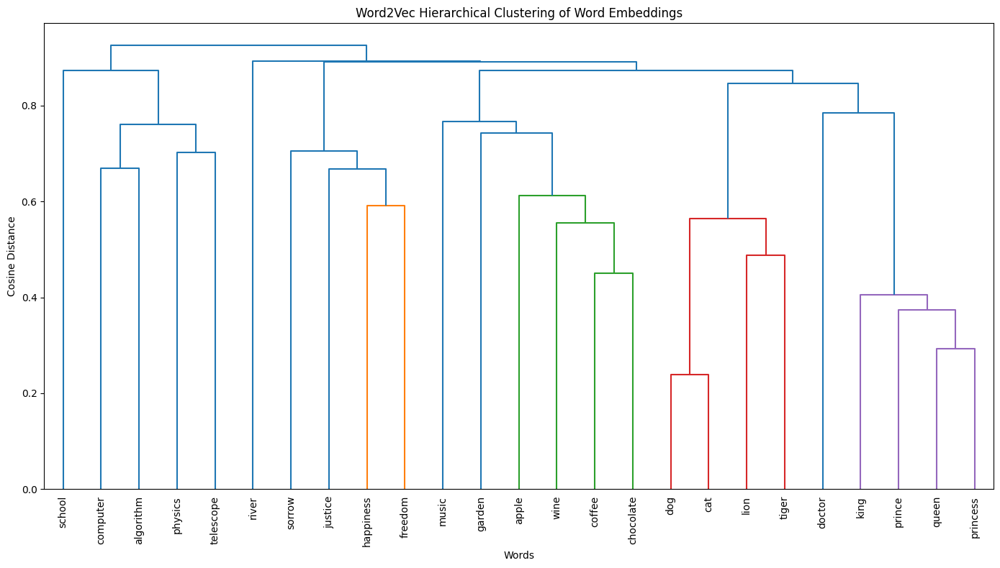

In [16]:
plot_dendrogram(word2vec_model, new_words, "Word2Vec")

# Conclusions

### cosine similarity
| Word pair/category | GloVe | Word2Vec |
|---|---:|---:|
| Synonyms: big–huge | 0.8811 | 0.7810 |
| Antonyms: long–short | 0.8911 | 0.5768 |
| Same semantic field: coffee–cup | 0.7181 | 0.3560 |
| Unrelated: cat–car | 0.7421 | 0.2153 |
| Unrelated: sorrow–pencil | 0.4174 | 0.0537 |

- word2vec face diferenta intre tipuri diferite de ralatii (ca o ierarhie in care pe primul loc, cu cel maimare scor este sinonimia, apoi antonimia, apoi camp semantic s.a.m.d); glove trateaza relatiile de sinonimie, antonimie si camp semantic la acelasi nivel (scorurile sunt aproximativ egale) 
- word2vec face distinctia buna intre scorul celor care sunt unrelated si scorul celor care sunt related (in any way); glove esueaza sa faca distinctia asta si da un scor neasteptta de mare intre cuvinte fara legatura (cat-car)
=> word2vec are o reprezentare mai buna pe aceste exemple

### dendrograms
- glove s-a descurcta mai bine la legaturile ierarhice king-queen-prince-princess fata de word2vec
- word2vec s-a descurcat in general (la restul cuvintelor) mai bine decat glove